# Monte Carlo Option Pricing

This notebook uses Monte Carlo simulation to estimate the value of European call and put options.

Under the risk-neutral measure, the terminal asset price follows:

\[
S_T
=
S_0
\exp\left[
\left(r-\frac{\sigma^2}{2}\right)T
+
\sigma\sqrt{T}Z
\right]
\]

where \(Z\) is a standard normal random variable.

The option price is obtained by discounting the expected payoff:

\[
V_0=e^{-rT}\mathbb{E}^{Q}[\text{payoff}]
\]

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)

In [2]:
## at the money call in this case

initial_price = 100
strike_price = 100
risk_free_rate = 0.05
annual_volatility = 0.20
time_to_maturity = 1

n_simulations = 100_000

In [3]:
normal_shocks = rng.normal(
    loc=0,
    scale=1,
    size=n_simulations
)

terminal_prices = initial_price * np.exp(
    (
        risk_free_rate
        - 0.5 * annual_volatility**2
    )
    * time_to_maturity
    + annual_volatility
    * np.sqrt(time_to_maturity)
    * normal_shocks
)

terminal_prices[:10]

array([109.52070323,  83.69450839, 119.73254039, 124.37275304,
        69.75318957,  79.41873397, 105.71409855,  96.72981383,
       102.69977792,  86.88291438])

In [4]:
pd.Series(terminal_prices).describe()

count    100000.000000
mean        105.054866
std          21.324055
min          42.834646
25%          89.969148
50%         102.860062
75%         117.813598
max         280.512204
dtype: float64

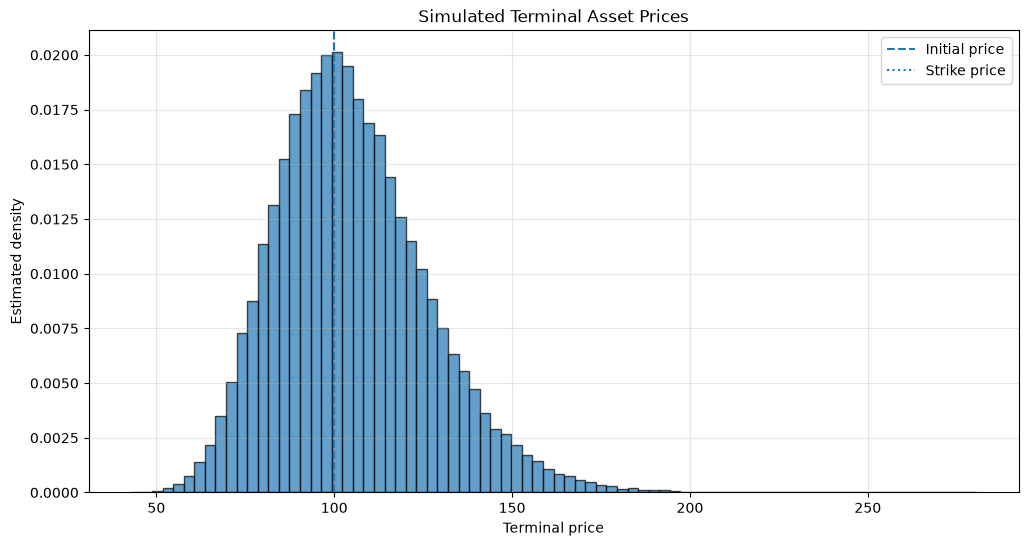

In [5]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.hist(
    terminal_prices,
    bins=80,
    density=True,
    edgecolor="black",
    alpha=0.7
)

ax.axvline(
    initial_price,
    linestyle="--",
    label="Initial price"
)

ax.axvline(
    strike_price,
    linestyle=":",
    label="Strike price"
)

ax.set_title("Simulated Terminal Asset Prices")
ax.set_xlabel("Terminal price")
ax.set_ylabel("Estimated density")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

In [6]:
call_payoffs = np.maximum(
    terminal_prices - strike_price,
    0
)

call_payoffs[:10]

array([ 9.52070323,  0.        , 19.73254039, 24.37275304,  0.        ,
        0.        ,  5.71409855,  0.        ,  2.69977792,  0.        ])

In [7]:
discount_factor = np.exp(
    -risk_free_rate * time_to_maturity
)

call_price_mc = (
    discount_factor
    * call_payoffs.mean()
)

call_price_mc

np.float64(10.420541193153111)

In [8]:
put_payoffs = np.maximum(
    strike_price - terminal_prices,
    0
)

put_price_mc = (
    discount_factor
    * put_payoffs.mean()
)

put_price_mc

np.float64(5.612203851328205)

In [9]:
option_prices = pd.Series({
    "monte_carlo_call_price": call_price_mc,
    "monte_carlo_put_price": put_price_mc,
    "mean_terminal_price": terminal_prices.mean(),
    "mean_call_payoff": call_payoffs.mean(),
    "mean_put_payoff": put_payoffs.mean(),
    "discount_factor": discount_factor
})

option_prices

monte_carlo_call_price     10.420541
monte_carlo_put_price       5.612204
mean_terminal_price       105.054866
mean_call_payoff           10.954814
mean_put_payoff             5.899948
discount_factor             0.951229
dtype: float64

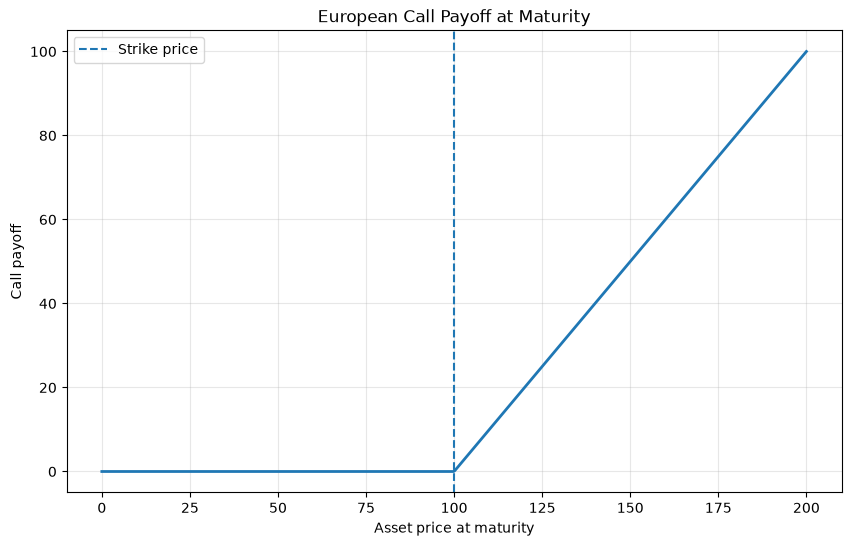

In [10]:
price_grid = np.linspace(
    0,
    2 * strike_price,
    500
)

call_payoff_grid = np.maximum(
    price_grid - strike_price,
    0
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    price_grid,
    call_payoff_grid,
    linewidth=2
)

ax.axvline(
    strike_price,
    linestyle="--",
    label="Strike price"
)

ax.set_title("European Call Payoff at Maturity")
ax.set_xlabel("Asset price at maturity")
ax.set_ylabel("Call payoff")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

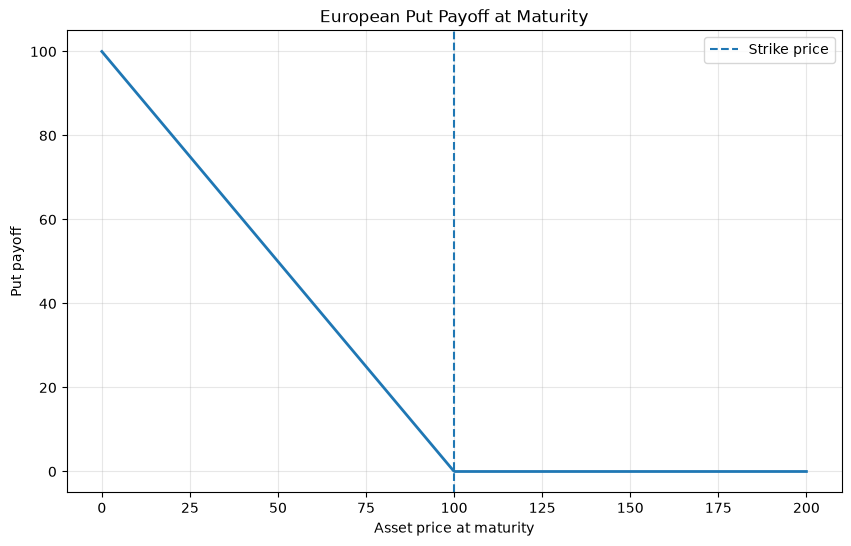

In [11]:
put_payoff_grid = np.maximum(
    strike_price - price_grid,
    0
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    price_grid,
    put_payoff_grid,
    linewidth=2
)

ax.axvline(
    strike_price,
    linestyle="--",
    label="Strike price"
)

ax.set_title("European Put Payoff at Maturity")
ax.set_xlabel("Asset price at maturity")
ax.set_ylabel("Put payoff")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

In [12]:
call_probability_itm = np.mean(
    terminal_prices > strike_price
)

put_probability_itm = np.mean(
    terminal_prices < strike_price
)

pd.Series({
    "call_probability_in_the_money": call_probability_itm,
    "put_probability_in_the_money": put_probability_itm
})

call_probability_in_the_money    0.5575
put_probability_in_the_money     0.4425
dtype: float64

In [13]:
discounted_call_payoffs = (
    discount_factor * call_payoffs
)

call_standard_error = (
    discounted_call_payoffs.std(ddof=1)
    / np.sqrt(n_simulations)
)

call_standard_error

np.float64(0.046769902520818175)

In [14]:
confidence_level_multiplier = 1.96

call_confidence_interval = (
    call_price_mc
    - confidence_level_multiplier * call_standard_error,
    call_price_mc
    + confidence_level_multiplier * call_standard_error
)

call_confidence_interval

(np.float64(10.328872184212308), np.float64(10.512210202093915))

In [15]:
print(f"Monte Carlo call price: {call_price_mc:.4f}")
print(f"Standard error: {call_standard_error:.4f}")
print(
    "95% confidence interval: "
    f"[{call_confidence_interval[0]:.4f}, "
    f"{call_confidence_interval[1]:.4f}]"
)

Monte Carlo call price: 10.4205
Standard error: 0.0468
95% confidence interval: [10.3289, 10.5122]


In [16]:
from scipy.stats import norm

d1 = (
    np.log(initial_price / strike_price)
    + (
        risk_free_rate
        + 0.5 * annual_volatility**2
    )
    * time_to_maturity
) / (
    annual_volatility
    * np.sqrt(time_to_maturity)
)

d2 = (
    d1
    - annual_volatility
    * np.sqrt(time_to_maturity)
)

call_price_bs = (
    initial_price * norm.cdf(d1)
    - strike_price
    * discount_factor
    * norm.cdf(d2)
)

put_price_bs = (
    strike_price
    * discount_factor
    * norm.cdf(-d2)
    - initial_price
    * norm.cdf(-d1)
)

In [17]:
price_comparison = pd.DataFrame({
    "Monte Carlo": [
        call_price_mc,
        put_price_mc
    ],
    "Black-Scholes": [
        call_price_bs,
        put_price_bs
    ]
}, index=["Call", "Put"])

price_comparison["Absolute error"] = np.abs(
    price_comparison["Monte Carlo"]
    - price_comparison["Black-Scholes"]
)

price_comparison

,Monte Carlo,Black-Scholes,Absolute error
Call,10.420541,10.450584,0.030042
Put,5.612204,5.573526,0.038678


In [18]:
black_scholes_inside_interval = (
    call_confidence_interval[0]
    <= call_price_bs
    <= call_confidence_interval[1]
)

black_scholes_inside_interval

np.True_

In [19]:
monte_carlo_parity_left = (
    call_price_mc - put_price_mc
)

parity_right = (
    initial_price
    - strike_price * discount_factor
)

pd.Series({
    "Monte Carlo C - P": monte_carlo_parity_left,
    "S0 - K exp(-rT)": parity_right,
    "absolute_difference": abs(
        monte_carlo_parity_left - parity_right
    )
})

Monte Carlo C - P      4.808337
S0 - K exp(-rT)        4.877058
absolute_difference    0.068720
dtype: float64

In [20]:
assert len(terminal_prices) == n_simulations
assert np.all(terminal_prices > 0)
assert np.all(call_payoffs >= 0)
assert np.all(put_payoffs >= 0)
assert call_price_mc > 0
assert put_price_mc > 0
assert call_confidence_interval[0] < call_confidence_interval[1]

print("Monte Carlo option pricing checks passed.")

Monte Carlo option pricing checks passed.


## Interpretation

Monte Carlo pricing estimates the value of an option by simulating terminal asset prices under the risk-neutral probability measure.

For each simulation:

1. a terminal asset price is generated;
2. the option payoff is calculated;
3. the payoff is discounted to the present.

The average discounted payoff provides an estimate of the option price.

The Monte Carlo result is close to the analytical Black-Scholes value, while the confidence interval quantifies the numerical uncertainty of the simulation.

The estimation error decreases as the number of simulations increases, although convergence is relatively slow because the standard error decreases proportionally to:

\[
\frac{1}{\sqrt{N}}
\]

## Conclusions

Monte Carlo simulation provides a flexible method for pricing financial derivatives.

For a simple European option, Black-Scholes offers a faster analytical solution. However, Monte Carlo becomes especially useful for derivatives with:

- multiple underlying assets;
- complex or path-dependent payoffs;
- several sources of uncertainty;
- models without a convenient closed-form solution.

The main limitation is computational cost, since reducing the standard error by half requires approximately four times as many simulations.